In [1]:
import polars as pl
from pathlib import Path

assay_scaf = pl.read_parquet(
    "../../data/sourced_antibody_v1/no_antibody/assay_scaffold.parquet"
)

true_dir = Path("../../data/abdb/complex_pdbfiles/cleaned")
pred_dir = Path("../../data/sourced_antibody_v1/no_antibody/af3_predictions")
mpnn_dir = Path("../../data/sourced_antibody_v1/no_antibody/proteinmpnn")

In [71]:
from mdaf3.AF3OutputParser import AF3Output
import MDAnalysis as mda
from MDAnalysis.analysis import rms
from MDAnalysis.analysis.align import alignto
import numpy as np

# compute RMSD of all MPNN res vs all AF3 res


def compute_epitope_chunk_rmsd_mpnn(row, mpnn_dir, af3_dir):
    try:
        af3_output = AF3Output(af3_dir / row["assay_scaffolded_epitope_id"])
        af3_u = af3_output.get_mda_universe()
    except Exception:
        row["overall_rmsd"] = None
        row["epitope_chunk_rmsd_vs_mpnn"] = None
        return row

    mpnn_u = mda.Universe(
        ((mpnn_dir / row["id"]) / str(row["contig_id"]))
        / (
            row["id"]
            + "_"
            + str(row["rfd_id"])
            + "_fixed_dldesign_"
            + str(row["mpnn_id"])
            + ".pdb"
        )
    )
    mpnn_ris = row["scaffolded_epitope_chunk_resindices"]
    af3_ris = row["assay_scaffolded_epitope_chunk_resindices"]

    assert mpnn_u.residues[mpnn_ris].sequence(format="string") == af3_u.residues[
        af3_ris
    ].sequence(format="string")

    start_idx = 2
    end_idx = start_idx + len(mpnn_u.select_atoms("segid A").residues)

    assert mpnn_u.residues.sequence(format="string") == af3_u.residues[
        start_idx:end_idx
    ].sequence(format="string")

    row["overall_rmsd"] = rms.rmsd(
        mpnn_u.select_atoms("segid A").select_atoms("backbone").positions,
        af3_u.residues[start_idx:end_idx].atoms.select_atoms("backbone").positions,
        superposition=True,
    )
    row["epitope_chunk_rmsd_vs_mpnn"] = rms.rmsd(
        mpnn_u.residues[mpnn_ris].atoms.select_atoms("backbone").positions,
        af3_u.residues[af3_ris].atoms.select_atoms("backbone").positions,
        superposition=True,
    )

    row["mean_pae"] = float(af3_output.get_pae_ndarr().mean())
    return row


# def superimpose_antibody(
#     None
# )


def num_clashing_interactions_mpnn(row, af3_dir, mpnn_dir, true_dir):
    af3_output = AF3Output(af3_dir / row["assay_scaffolded_epitope_id"])
    af3_u = af3_output.get_mda_universe()
    af3_ris = row["assay_scaffolded_epitope_chunk_resindices"]

    mpnn_u = mda.Universe(
        ((mpnn_dir / row["id"]) / str(row["contig_id"]))
        / (
            row["id"]
            + "_"
            + str(row["rfd_id"])
            + "_fixed_dldesign_"
            + str(row["mpnn_id"])
            + ".pdb"
        )
    )
    mpnn_ris = row["scaffolded_epitope_chunk_resindices"]

    true_u = mda.Universe(true_dir / (row["id"] + ".pdb"))
    true_ris = row["epitope_chunk_resindices"]

    alignto(
        mpnn_u.residues[mpnn_ris].atoms.select_atoms("backbone"),
        true_u.residues[true_ris].atoms.select_atoms("backbone"),
    )

    # print(mpnn_u.residues[mpnn_ris].atoms.select_atoms("name CA").positions[:10])
    # print(true_u.residues[true_ris].atoms.select_atoms("name CA").positions[:10])

    mpnn_combined_u = mda.Merge(
        mpnn_u.atoms, true_u.atoms.select_atoms("segid B or segid C")
    )
    # mpnn_combined_u.atoms.write("mpnn_combined.pdb")

    tmp_boolmask = np.full(len(mpnn_u.residues), False)
    tmp_boolmask[mpnn_ris] = True
    unintended_res = mpnn_combined_u.select_atoms("segid A").residues[~tmp_boolmask]

    row["mpnn_clash_resindices"] = list(
        unintended_res.atoms.select_atoms(
            "segid A and (not name H*) and around 4 ((segid B or segid C) and (not name H*))"
        ).residues.resindices
    )

    alignto(
        af3_u.residues[af3_ris].atoms.select_atoms("backbone"),
        true_u.residues[true_ris].atoms.select_atoms("backbone"),
    )
    # af3_u.atoms.chainIDs = ["D"] * len(af3_u.atoms)
    # af3_combined_u = mda.Merge(
    #     af3_u.atoms, true_u.atoms
    # )
    # af3_combined_u.atoms.write("af3_combined.pdb")
    af3_combined_u = mda.Merge(
        af3_u.atoms, true_u.atoms.select_atoms("segid B or segid C")
    )
    tmp_boolmask = np.full(len(af3_u.residues), False)
    tmp_boolmask[af3_ris] = True
    unintended_res = af3_combined_u.select_atoms("segid A").residues[~tmp_boolmask]
    # print(unintended_res)
    # print(unintended_res.atoms.select_atoms("segid A and (not name H*)"))

    l = list(
        unintended_res.atoms.select_atoms(
            "segid A and (not name H*) and around 4 ((segid B or segid C) and (not name H*))"
        ).residues.resindices
    )

    if len(l) > 0:
        print("Clash dectected")

    row["af3_clash_resindices"] = l

    return row


# def compute_epitope_chunk_rmsd_true(row, true_dir, pred_dir):

#     true_u = mda.Universe(true_dir / (row["id"] + ".pdb"))
#     true_ris = row["epitope_chunk_resindices"]
#     true_epi_ris = row["epitope_resindices"]

#     af3_output = AF3Output(pred_dir / row["assay_scaffolded_epitope_id"])
#     pred_u = af3_output.get_mda_universe()
#     pred_ris = row["assay_scaffolded_epitope_chunk_resindices"]
#     pred_epi_ris = row["assay_scaffolded_epitope_resindices"]

#     assert pred_u.residues[pred_ris].sequence(format="string") == true_u.residues[
#         true_ris
#     ].sequence(format="string")

#     row["ptm"] = af3_output.get_summary_metrics()["ptm"]
#     row["epitope_chunk_rmsd_vs_true"] = rms.rmsd(
#         pred_u.residues[pred_ris].atoms.select_atoms("backbone").positions,
#         true_u.residues[true_ris].atoms.select_atoms("backbone").positions,
#         superposition=True,
#     )
#     row["epitope_rmsd_vs_true"] = rms.rmsd(
#         pred_u.residues[pred_epi_ris].atoms.select_atoms("backbone").positions,
#         true_u.residues[true_epi_ris].atoms.select_atoms("backbone").positions,
#         superposition=True,
#     )
#     return row

In [ ]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt


def plot_success_bar(df: pl.DataFrame, title: str = ""):
    """
    Expects columns:
      - id (str)
      - prop_success (float in [0,1])
      - total_attempts (int)
      - epitope_chunks (int)
    """
    # order by id for stable plotting (optional)
    df2 = df.select(
        [
            "id",
            "prop_success",
            "total_attempts",
            "epitope_chunks",
            "num_epitope_chunk_res",
        ]
    )

    ids = df2.get_column("id").to_list()
    props = df2.get_column("prop_success").to_numpy()
    atts = df2.get_column("total_attempts").to_numpy()
    chunks = df2.get_column("epitope_chunks").to_numpy()
    res = df2.get_column("num_epitope_chunk_res").to_numpy()

    n = len(ids)
    fig, ax = plt.subplots(figsize=(12, 4.5))

    x = np.arange(n)
    bars = ax.bar(x, props, width=0.75, color="tab:blue", edgecolor="black", alpha=0.8)

    # Annotations: "attempts, chunks"
    # e.g., "n=12, chunks=3"
    for xi, bar, n_attempts, n_chunks, n_res in zip(x, bars, atts, chunks, res):
        y = bar.get_height()
        ax.text(
            xi,
            y + 0.25,  # slight offset above the bar
            f"n={n_attempts}\nchunks={n_chunks}\nn_res={n_res}",
            ha="center",
            va="top",
            fontsize=8,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(ids, rotation=45, ha="right")
    ax.set_ylabel("prop. PAE < 5, total RMSD <= 2, motif RMSD <= 1")
    ax.set_ylim(0, max(1.0, float(np.nanmax(props)) + 0.1))
    if title:
        ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)

    fig.tight_layout()
    return fig, ax

In [5]:
from mdaf3.FeatureExtraction import serial_apply, split_apply_combine
import warnings

warnings.filterwarnings("ignore")

rmsd = split_apply_combine(
    assay_scaf, compute_epitope_chunk_rmsd_mpnn, mpnn_dir, pred_dir, chunksize=15
)

100%|██████████| 1052608/1052608 [03:45<00:00, 4671.93it/s]


In [ ]:
rmsd_clean = rmsd.filter(pl.col("overall_rmsd").is_not_null())

rmsd_clean = rmsd_clean.with_columns(
    pl.when(
        pl.col("mean_pae") < 5,
        pl.col("overall_rmsd") <= 2,
        pl.col("epitope_chunk_rmsd_vs_mpnn") <= 1,
    )
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("success")
)

rmsd_clean.write_parquet("rmsd_clean_cache.parquet")

pl.Config.set_tbl_rows(-1)
rmsd_clean.group_by(pl.col("epitope_chunks")).agg(
    (pl.col("success").sum() / pl.len()).alias("prop_success")
).sort(by="epitope_chunks")

epitope_chunks,prop_success
i64,f64
1,0.018868
2,0.017339
3,0.000585
4,0.000244
5,0.0
6,0.0
7,0.0
8,0.0
9,0.0


(<Figure size 1200x450 with 1 Axes>,
 <Axes: ylabel='prop. PAE < 5, total RMSD <= 2, motif RMSD <= 1'>)

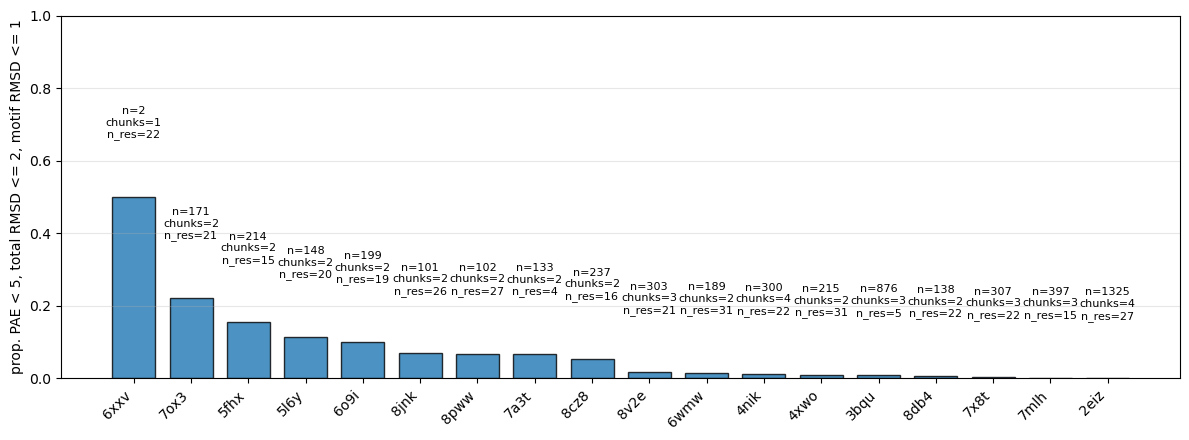

In [ ]:
rmsd_by_pdb = (
    rmsd_clean.group_by(pl.col("id").str.slice(0, 4))
    .agg(
        (pl.col("success").sum() / pl.len()).alias("prop_success"),
        pl.len().alias("total_attempts"),
        pl.col("epitope_chunks").first(),
        pl.col("epitope_chunk_resindices")
        .first()
        .list.len()
        .alias("num_epitope_chunk_res"),
    )
    .filter(pl.col("prop_success") > 0.0)
    .sort(by="prop_success", descending=True)
)

plot_success_bar(rmsd_by_pdb)

0.08053066449435588


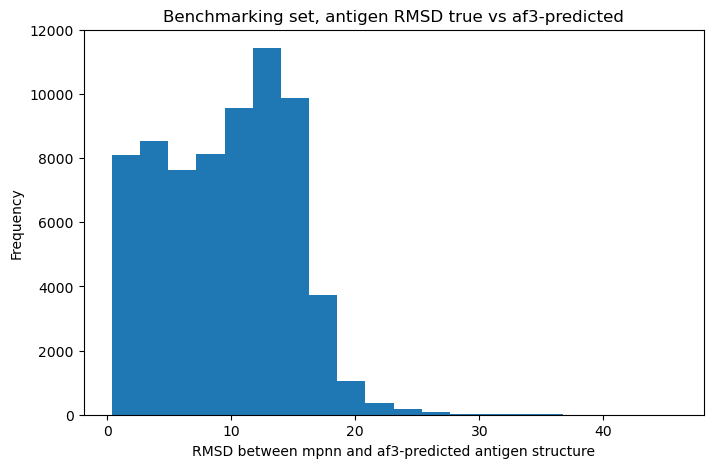

In [9]:
import matplotlib.pyplot as plt

fix, ax = plt.subplots(figsize=(8, 5))
ax.set_title("Benchmarking set, antigen RMSD true vs af3-predicted")
ax.set_xlabel("RMSD between mpnn and af3-predicted antigen structure")
ax.set_ylabel("Frequency")
parts = ax.hist(rmsd_clean.select("overall_rmsd").to_series(), bins=20)

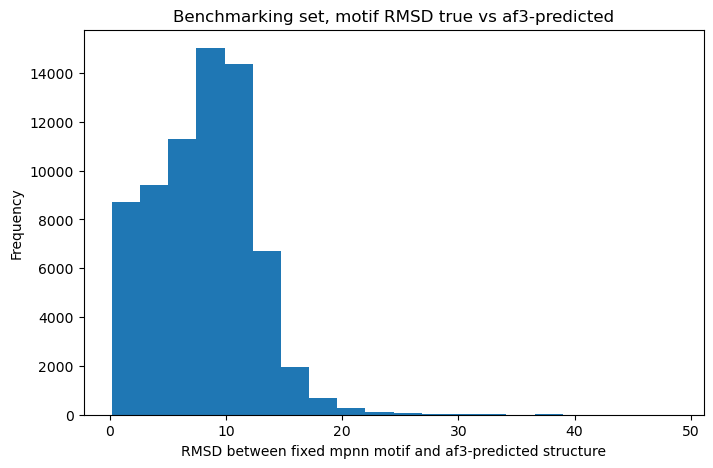

In [8]:
import matplotlib.pyplot as plt

fix, ax = plt.subplots(figsize=(8, 5))
ax.set_title("Benchmarking set, motif RMSD true vs af3-predicted")
ax.set_xlabel("RMSD between fixed mpnn motif and af3-predicted structure")
ax.set_ylabel("Frequency")
parts = ax.hist(rmsd.select("epitope_chunk_rmsd_vs_mpnn").to_series(), bins=20)

## Clashing interaction quantification


In [72]:
## clashing interactions
from mdaf3.FeatureExtraction import serial_apply
import polars as pl
from pathlib import Path

import warnings

warnings.filterwarnings("ignore")

true_dir = Path("../../data/abdb/complex_pdbfiles/cleaned")
pred_dir = Path("../../data/sourced_antibody_v1/no_antibody/af3_predictions")
mpnn_dir = Path("../../data/sourced_antibody_v1/no_antibody/proteinmpnn")

rmsd_clean = pl.read_parquet("rmsd_clean_cache.parquet")

clashes = serial_apply(
    rmsd_clean.filter(pl.col("success")),
    num_clashing_interactions_mpnn,
    pred_dir,
    mpnn_dir,
    true_dir,
)

Processing rows: 100%|██████████| 171/171 [00:16<00:00, 10.45it/s]


In [73]:
clashes

antigen_seq,heavy_seq,light_seq,epitope_seq,id,resolution,light_original_segid,heavy_original_segid,antigen_original_segid,r_work,r_free,antigen_ncbi_taxonomy_id,light_ncbi_taxonomy_id,heavy_ncbi_taxonomy_id,epitope_resindices,epitope_boolmask,contig_string,epitope_chunks,contig_gaps,contig_min,contig_id,contig_length,epitope_chunk_resindices,scaffolded_epitope_chunk_resindices,scaffolded_epitope_resindices,rfd_id,mpnn_id,scaffolded_epitope_seq,assay_scaffolded_epitope_seq,assay_scaffolded_epitope_id,assay_scaffolded_epitope_chunk_resindices,assay_scaffolded_epitope_resindices,overall_rmsd,epitope_chunk_rmsd_vs_mpnn,mean_pae,success,mpnn_clash_resindices,af3_clash_resindices
str,str,str,str,str,f64,str,str,str,f64,f64,i64,i64,i64,list[i64],list[bool],str,i64,list[i64],list[i64],i64,str,list[i64],list[i64],list[i64],i64,i64,str,str,str,list[i64],list[i64],f64,f64,f64,bool,list[null],list[null]
"""KVFGRCELAAAMKRHGLDNYRGYSLGNWVC…","""QVQLQESGPGLMKPSETLSLTCSVSGDSIR…","""EIVMTQSPATLSVSPGERATLSCRASQSIG…","""RHGNYRWWLNTNKKISDG""","""2eiz_0P""",1.9,"""A""","""B""","""C""",0.214,0.253,9031,9606,9606,"[13, 14, … 101]","[false, false, … false]","""9-9/A14-21/16-16/A62-63/22-22/…",4,"[9, 16, … 8]","[0, 12, … 0]",30,"""104-104""","[13, 14, … 101]","[9, 10, … 95]","[9, 10, … 95]",5,1,"""SAAAEEFLKRHGLDNYRGLSPEEIAKVLDY…","""GASAAAEEFLKRHGLDNYRGLSPEEIAKVL…","""4172e02f3792edbd85690a087f6e28…","[11, 12, … 97]","[11, 12, … 97]",1.119167,0.99063,4.997781,true,[],[]
"""ETTVTQSPASLSMSIGEKVTIRCITSTDID…","""RITLKESGPPLVKPTQTLTLTCSFSGFSLS…","""ALQLTQSPSSLSASVGDRITITCRASQGVT…","""DDDY""","""3bqu_0P""",3.0,"""A""","""B""","""C""",0.276,0.295,10090,9606,9606,"[22, 24, … 59]","[false, false, … false]","""23-23/A23-25/14-14/A43-43/39-3…",3,"[23, 14, … 23]","[0, 4, … 0]",11,"""104-104""","[22, 23, … 59]","[23, 24, … 80]","[23, 25, … 80]",3,2,"""EEALKTYEALLKAFEEAIAQEGIDDDTFWA…","""GAEEALKTYEALLKAFEEAIAQEGIDDDTF…","""a2a9e4c57ef961eb4b91421d2e61bb…","[25, 26, … 82]","[25, 27, … 82]",0.856534,0.968138,4.296371,true,[],[]
"""ETTVTQSPASLSMSIGEKVTIRCITSTDID…","""RITLKESGPPLVKPTQTLTLTCSFSGFSLS…","""ALQLTQSPSSLSASVGDRITITCRASQGVT…","""DDDY""","""3bqu_0P""",3.0,"""A""","""B""","""C""",0.276,0.295,10090,9606,9606,"[22, 24, … 59]","[false, false, … false]","""30-30/A23-25/17-17/A43-43/22-2…",3,"[30, 17, … 30]","[0, 4, … 0]",26,"""104-104""","[22, 23, … 59]","[30, 31, … 73]","[30, 32, … 73]",0,2,"""MEKKEKLKKMFKEVFEEILEHLEEHPDEIV…","""GAMEKKEKLKKMFKEVFEEILEHLEEHPDE…","""d952b15284dfe4a2128b12aa122d2e…","[32, 33, … 75]","[32, 34, … 75]",0.604227,0.541808,4.903242,true,[],[]
"""ETTVTQSPASLSMSIGEKVTIRCITSTDID…","""RITLKESGPPLVKPTQTLTLTCSFSGFSLS…","""ALQLTQSPSSLSASVGDRITITCRASQGVT…","""DDDY""","""3bqu_0P""",3.0,"""A""","""B""","""C""",0.276,0.295,10090,9606,9606,"[22, 24, … 59]","[false, false, … false]","""30-30/A23-25/17-17/A43-43/22-2…",3,"[30, 17, … 30]","[0, 4, … 0]",26,"""104-104""","[22, 23, … 59]","[30, 31, … 73]","[30, 32, … 73]",0,5,"""SAALEELRKKFLEVTKEILEKLEKNPEEII…","""GASAALEELRKKFLEVTKEILEKLEKNPEE…","""c3e390830cba5d16b374ae46fe8d82…","[32, 33, … 75]","[32, 34, … 75]",0.678446,0.436435,4.940475,true,[],[]
"""ETTVTQSPASLSMSIGEKVTIRCITSTDID…","""RITLKESGPPLVKPTQTLTLTCSFSGFSLS…","""ALQLTQSPSSLSASVGDRITITCRASQGVT…","""DDDY""","""3bqu_0P""",3.0,"""A""","""B""","""C""",0.276,0.295,10090,9606,9606,"[22, 24, … 59]","[false, false, … false]","""24-24/A23-25/19-19/A43-43/33-3…",3,"[24, 19, … 23]","[0, 4, … 0]",27,"""104-104""","[22, 23, … 59]","[24, 25, … 80]","[24, 26, … 80]",2,1,"""MGSEMLRRLAERFLELLEKGEEKLDDDTIA…","""GAMGSEMLRRLAERFLELLEKGEEKLDDDT…","""4b00294c81b14c65d2c0fd8cab52f6…","[26, 27, … 82]","[26, 28, … 82]",0.69285,0.5323,4.988639,true,[],[]
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""GNVSQEDIIRALAEPLIDDGMVEKEFADHV…","""EVQLVESGGGLVKPGGSLRLSCSASGFDFD…","""YELTQETGVSVALGRTVTITCRGDSLRSHY…","""LQWYRNWFTNLNKI""","""8v2e_0P""",2.62,"""B""","""A""","""C""",0.2282,0.2763,32630,9606,9606,"[40, 41, … 110]","[false, false, … false]"

In [103]:
from MDAnalysis.analysis.align import alignto
from io import StringIO
from MDAnalysis.lib.util import NamedStream
import py3Dmol

row = list(rmsd.sort(by="epitope_chunk_rmsd").iter_rows(named=True))[0]
af3_output = AF3Output(pred_dir / row["assay_scaffolded_epitope_id"])
pred_u = af3_output.get_mda_universe()
pred_ris = row["assay_scaffolded_epitope_chunk_resindices"]

true_u = mda.Universe(true_dir / (row["id"] + ".pdb"))
true_ris = row["epitope_chunk_resindices"]

print(
    alignto(
        pred_u.residues[pred_ris].atoms.select_atoms("name CA"),
        true_u.residues[true_ris].atoms.select_atoms("name CA"),
    )
)

view = py3Dmol.view()
pred_ns = NamedStream(StringIO(), "tmp.pdb")
pred_u.atoms.write(pred_ns)

true_ns = NamedStream(StringIO(), "tmp.pdb")
true_u.select_atoms("segid A").write(true_ns)


view.addModelsAsFrames(
    pred_ns.stream.getvalue(),
)
view.addModelsAsFrames(true_ns.stream.getvalue())
view.setStyle({"model": -1}, {"cartoon": {"color": "blue"}})
view.setStyle({"model": 0}, {"cartoon": {"color": "red"}})
view.zoomTo()
view.show()

(np.float64(8.913745101686937), 6.396634355490706)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [102]:
row["contig_string"]

'14-14/A23-27/23-23/A42-50/24-24/A77-82/7-7/A142-143/14-14/0 B1-117/0 C1-110/0 '

In [96]:
row["contig_string"]

'9-9/A23-27/12-12/A42-50/47-47/A77-82/5-5/A142-143/9-9/0 B1-117/0 C1-110/0 '

In [ ]:
view = py3Dmol.view(width=400, height=300)

with open(u.filename) as ifile:
    system_pdb = "".join([x for x in ifile])

with gzip.open(pred_u.filename, "rt") as ifile:
    system_cif = "".join([x for x in ifile])

view.addModelsAsFrames(system_cif)
view.addModelsAsFrames(system_pdb)
view.setStyle({"model": -1}, {"cartoon": {"color": "spectrum"}})
view.setStyle({"model": 0}, {"cartoon": {"color": "spectrum"}})
view.zoomTo()
view.show()

In [67]:
from io import StringIO
from MDAnalysis.lib.util import NamedStream

ns = NamedStream(StringIO(), "tmp.pdb")

with mda.Writer(ns) as W:
    W.write(true_u.atoms)

/home/lwoods/miniconda3/envs/episcaf-experiments/lib/python3.13/site-packages/MDAnalysis/coordinates/PDB.py:789: UserWarning: Unit cell dimensions not found. CRYST1 record set to unitary values.
  warnings.warn("Unit cell dimensions not found. "
/home/lwoods/miniconda3/envs/episcaf-experiments/lib/python3.13/site-packages/MDAnalysis/coordinates/PDB.py:1166: UserWarning: Found no information for attr: 'formalcharges' Using default value of '0'
  warnings.warn("Found no information for attr: '{}'"


In [70]:
ns.stream.getvalue()

'HEADER    \nTITLE     MDANALYSIS FRAMES FROM 0, STEP 1: Created by PDBWriter\nREMARK     285 UNITARY VALUES FOR THE UNIT CELL AUTOMATICALLY SET\nREMARK     285 BY MDANALYSIS PDBWRITER BECAUSE UNIT CELL INFORMATION\nREMARK     285 WAS MISSING.\nREMARK     285 PROTEIN DATA BANK CONVENTIONS REQUIRE THAT\nREMARK     285 CRYST1 RECORD IS INCLUDED, BUT THE VALUES ON\nREMARK     285 THIS RECORD ARE MEANINGLESS.\nCRYST1    1.000    1.000    1.000  90.00  90.00  90.00 P 1           1\nREMARK     285 UNITARY VALUES FOR THE UNIT CELL AUTOMATICALLY SET\nREMARK     285 BY MDANALYSIS PDBWRITER BECAUSE UNIT CELL INFORMATION\nREMARK     285 WAS MISSING.\nREMARK     285 PROTEIN DATA BANK CONVENTIONS REQUIRE THAT\nREMARK     285 CRYST1 RECORD IS INCLUDED, BUT THE VALUES ON\nREMARK     285 THIS RECORD ARE MEANINGLESS.\nMODEL        1\nATOM      1  N   CYS A   1      19.960  11.742  26.156  1.00 32.73      A    N  \nATOM      2  CA  CYS A   1      21.176  11.819  27.021  1.00 30.94      A    C  \nATOM   

In [72]:
view = py3Dmol.view(width=400, height=300)


view.addModelsAsFrames(ns.stream.getvalue())
view.setStyle({"model": -1}, {"cartoon": {"color": "spectrum"}})
view.setStyle({"model": 0}, {"cartoon": {"color": "spectrum"}})
view.zoomTo()
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.